In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import Ridge, HuberRegressor

In [9]:
df = pd.read_csv("Q2.csv")
df.tail()

,1,2,3,4,5,6,7,8,9,10,...,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000
0,13,29,44,55,61,72,200,96,112,120,...,21680,21692,21697,21705,21711,21729,21742,21746,21763,21777
1,-3980,-3883,-3832,0,-3839,-3788,-3695,-3663,-3669,0,...,7130,7150,7117,7023,7064,0,7027,6929,6954,6867
2,-3959,-4058,-4131,-4033,-4009,-3941,-3996,-4071,-3971,-4021,...,-254,-296,-303,0,-327,-274,-358,-278,-346,-299


In [15]:
row3 = df.iloc[2].astype(int).values
row3

array([-3959, -4058, -4131, ...,  -278,  -346,  -299])

In [21]:
df.iloc[2].isnull().sum()

0

In [23]:
#شناسایی داده های پرت با روش z_score
z_scores = stats.zscore(row3)
z_outliers = np.where(np.abs(z_scores) > 3)[0]
z_outliers

array([], dtype=int64)

In [25]:
#شناسایی داده های پرت با استفاده از  روش IQR
q1 = np.percentile(row3, 25)
q3 = np.percentile(row3, 75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
iqr_outliers = np.where((row3 < lower_bound) | (row3 > upper_bound))[0]
iqr_outliers

array([], dtype=int64)

In [27]:
iso_forest = IsolationForest(contamination=0.05, random_state=42)
row3_reshaped = row_data.reshape(-1, 1)
iso_outliers = np.where(iso_forest.fit_predict(row3_reshaped) == -1)[0]

In [29]:
iso_outliers

array([ 790,  801,  802,  803,  804,  813,  814,  816,  817,  818,  819,
        820,  830,  831,  832,  833,  836,  837,  838,  840,  842,  843,
        844,  845,  846,  847,  848,  849,  850,  851,  852,  853,  854,
        855, 1521, 1528, 1532, 1536, 1538, 1539, 1540, 1541, 1542, 1543,
       1544, 1545, 1546, 1547, 1548, 1550, 1551, 1552, 1553, 1554, 1555,
       1556, 1557, 1558, 1559, 1560, 1561, 1562, 1563, 1564, 1565, 1764,
       1765, 1766, 1767, 1770, 1772, 1773, 1774, 1776, 1777, 1778, 1779,
       1780, 1781, 1782, 1783, 1784, 1787, 1789, 1790, 1791, 1792, 1793,
       1794, 1795, 1796, 1797, 1798, 1799, 1800, 1801, 1845, 1847, 1848,
       1849], dtype=int64)

In [31]:
row3_cleaned = np.delete(row3, iso_outliers)
row3_cleaned

array([-3959, -4058, -4131, ...,  -278,  -346,  -299])

Final coefficients with MSE: [-0.12106707 -1.63294943]
Final coefficients with MAE: [-7.57316000e-05 -6.69569725e-02]


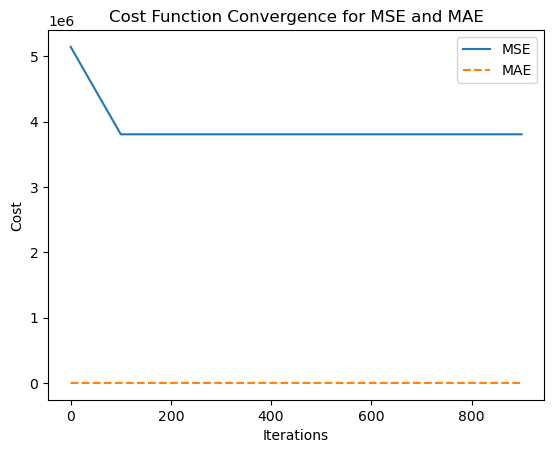

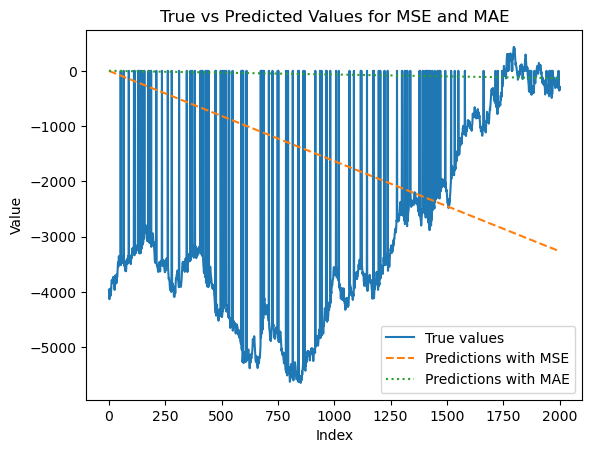

In [47]:
# Convert the row to a matrix of feature vectors (for simplicity, use X = [1, 2, 3, ..., N])
X = np.array([np.arange(1, len(row3) + 1)])

# Add a bias term to the feature matrix
X = np.vstack([np.ones(X.shape[1]), X])  # Adding a row of 1s for the bias term

# Define the true values (row2)
y = row3

# Initialize coefficients (beta) for the linear model
beta = np.zeros(X.shape[0])

# Define the learning rate and number of iterations
learning_rate = 0.0000001  
iterations = 1000

# Define the Mean Squared Error (MSE) cost function
def compute_mse(X, y, beta):
    m = len(y)
    predictions = np.dot(X.T, beta)
    mse = (1 / (2 * m)) * np.sum((predictions - y) ** 2)
    return mse

# Define the Mean Absolute Error (MAE) cost function
def compute_mae(X, y, beta):
    m = len(y)
    predictions = np.dot(X.T, beta)
    mae = (1 / m) * np.sum(np.abs(predictions - y))
    return mae

# Define the gradient descent algorithm for MSE
def gradient_descent_mse(X, y, beta, learning_rate, iterations):
    m = len(y)
    cost_history = []

    for i in range(iterations):
        predictions = np.dot(X.T, beta)
        errors = predictions - y
        gradients = (1 / m) * np.dot(X, errors)
        beta = beta - learning_rate * gradients

        # Store the cost for every 100 iterations to monitor the progress
        if i % 100 == 0:
            cost = compute_mse(X, y, beta)
            cost_history.append(cost)

    return beta, cost_history

# Define the gradient descent algorithm for MAE
def gradient_descent_mae(X, y, beta, learning_rate, iterations):
    m = len(y)
    cost_history = []

    for i in range(iterations):
        predictions = np.dot(X.T, beta)
        errors = predictions - y
        gradients = (1 / m) * np.dot(X, np.sign(errors))  # Using the sign of errors for MAE
        beta = beta - learning_rate * gradients

        # Store the cost for every 100 iterations to monitor the progress
        if i % 100 == 0:
            cost = compute_mae(X, y, beta)
            cost_history.append(cost)

    return beta, cost_history

# Train the model using gradient descent with MSE
beta_mse, cost_history_mse = gradient_descent_mse(X, y, beta, learning_rate, iterations)

# Train the model using gradient descent with MAE
beta_mae, cost_history_mae = gradient_descent_mae(X, y, beta, learning_rate, iterations)

# Output the final coefficients and plot the cost history
print("Final coefficients with MSE:", beta_mse)
print("Final coefficients with MAE:", beta_mae)

# Plot the cost history for both MSE and MAE
plt.plot(range(0, iterations, 100), cost_history_mse, label="MSE")
plt.plot(range(0, iterations, 100), cost_history_mae, label="MAE", linestyle='--')
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.legend()
plt.title('Cost Function Convergence for MSE and MAE')
plt.show()

# Use the final model to make predictions
predictions_mse = np.dot(X.T, beta_mse)
predictions_mae = np.dot(X.T, beta_mae)

# Display the predictions
plt.plot(np.arange(1, len(y) + 1), y, label="True values")
plt.plot(np.arange(1, len(y) + 1), predictions_mse, label="Predictions with MSE", linestyle='--')
plt.plot(np.arange(1, len(y) + 1), predictions_mae, label="Predictions with MAE", linestyle=':')
plt.xlabel('Index')
plt.ylabel('Value')
plt.legend()
plt.title('True vs Predicted Values for MSE and MAE')
plt.show()

Final coefficients with MSE: [-1.1775221  -1.77357189]


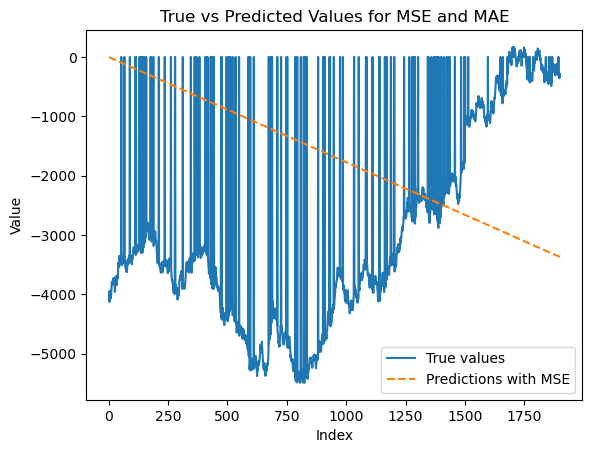

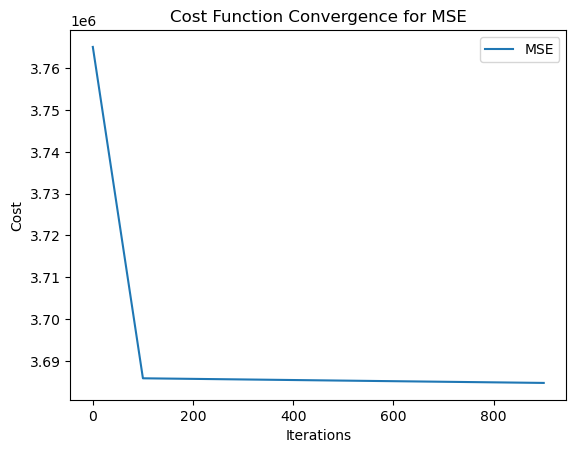

In [49]:
# Convert the row to a matrix of feature vectors (for simplicity, use X = [1, 2, 3, ..., N])
X = np.array([np.arange(1, len(row3_cleaned) + 1)])

# Add a bias term to the feature matrix
X = np.vstack([np.ones(X.shape[1]), X])  # Adding a row of 1s for the bias term

# Define the true values (row2)
y = row3_cleaned

# Initialize coefficients (beta) for the linear model
beta = np.zeros(X.shape[0])

# Define the learning rate and number of iterations
learning_rate = 0.000001  
iterations = 1000

# Define the Mean Squared Error (MSE) cost function
def compute_mse(X, y, beta):
    m = len(y)
    predictions = np.dot(X.T, beta)
    mse = (1 / (2 * m)) * np.sum((predictions - y) ** 2)
    return mse
# Define the gradient descent algorithm for MSE
def gradient_descent_mse(X, y, beta, learning_rate, iterations):
    m = len(y)
    cost_history = []

    for i in range(iterations):
        predictions = np.dot(X.T, beta)
        errors = predictions - y
        gradients = (1 / m) * np.dot(X, errors)
        beta = beta - learning_rate * gradients

        # Store the cost for every 100 iterations to monitor the progress
        if i % 100 == 0:
            cost = compute_mse(X, y, beta)
            cost_history.append(cost)

    return beta, cost_history


# Train the model using gradient descent with MSE
beta_mse, cost_history_mse = gradient_descent_mse(X, y, beta, learning_rate, iterations)

# Output the final coefficients and plot the cost history
print("Final coefficients with MSE:", beta_mse)

predictions_mse = np.dot(X.T, beta_mse)


# Display the predictions
plt.plot(np.arange(1, len(y) + 1), y, label="True values")
plt.plot(np.arange(1, len(y) + 1), predictions_mse, label="Predictions with MSE", linestyle='--')
plt.xlabel('Index')
plt.ylabel('Value')
plt.legend()
plt.title('True vs Predicted Values for MSE and MAE')
plt.show()


# Plot the cost history for  MSE  
plt.plot(range(0, iterations, 100), cost_history_mse, label="MSE")
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.legend()
plt.title('Cost Function Convergence for MSE')
plt.show()

Final coefficients with MAE: [-0.00472789 -1.61195383]


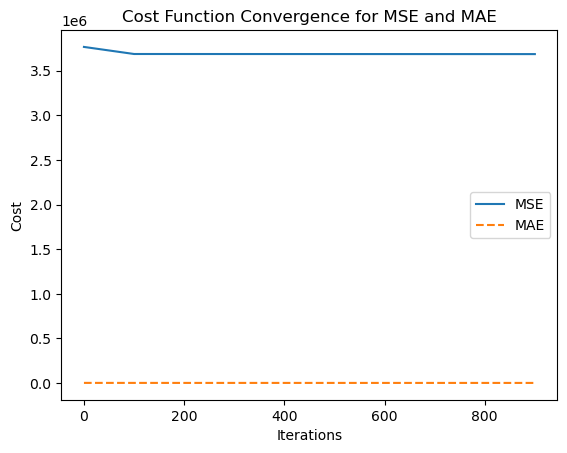

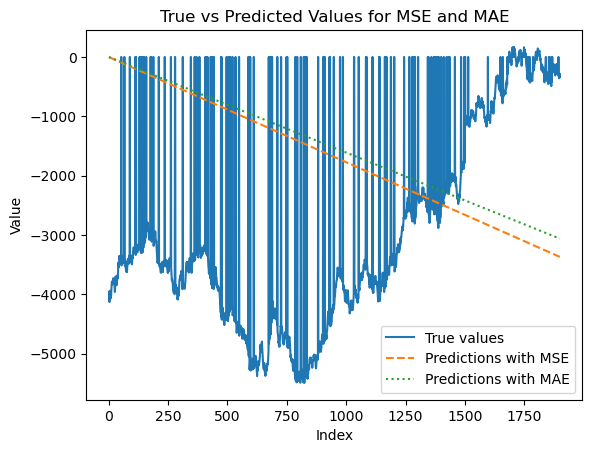

In [51]:
# Convert the row to a matrix of feature vectors (for simplicity, use X = [1, 2, 3, ..., N])
X = np.array([np.arange(1, len(row3_cleaned) + 1)])

# Add a bias term to the feature matrix
X = np.vstack([np.ones(X.shape[1]), X])  # Adding a row of 1s for the bias term

# Define the true values (row2)
y = row3_cleaned

# Initialize coefficients (beta) for the linear model
beta = np.zeros(X.shape[0])

# Define the learning rate and number of iterations
learning_rate = 0.00001  
iterations = 1000

# Define the Mean Absolute Error (MAE) cost function
def compute_mae(X, y, beta):
    m = len(y)
    predictions = np.dot(X.T, beta)
    mae = (1 / m) * np.sum(np.abs(predictions - y))
    return mae


# Define the gradient descent algorithm for MAE
def gradient_descent_mae(X, y, beta, learning_rate, iterations):
    m = len(y)
    cost_history = []

    for i in range(iterations):
        predictions = np.dot(X.T, beta)
        errors = predictions - y
        gradients = (1 / m) * np.dot(X, np.sign(errors))  # Using the sign of errors for MAE
        beta = beta - learning_rate * gradients

        # Store the cost for every 100 iterations to monitor the progress
        if i % 100 == 0:
            cost = compute_mae(X, y, beta)
            cost_history.append(cost)

    return beta, cost_history



# Train the model using gradient descent with MAE
beta_mae, cost_history_mae = gradient_descent_mae(X, y, beta, learning_rate, iterations)


print("Final coefficients with MAE:", beta_mae)

# Plot the cost history for both MSE and MAE
plt.plot(range(0, iterations, 100), cost_history_mse, label="MSE")
plt.plot(range(0, iterations, 100), cost_history_mae, label="MAE", linestyle='--')
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.legend()
plt.title('Cost Function Convergence for MSE and MAE')
plt.show()

# Use the final model to make predictions

predictions_mae = np.dot(X.T, beta_mae)

# Display the predictions
plt.plot(np.arange(1, len(y) + 1), y, label="True values")
plt.plot(np.arange(1, len(y) + 1), predictions_mse, label="Predictions with MSE", linestyle='--')
plt.plot(np.arange(1, len(y) + 1), predictions_mae, label="Predictions with MAE", linestyle=':')
plt.xlabel('Index')
plt.ylabel('Value')
plt.legend()
plt.title('True vs Predicted Values for MSE and MAE')
plt.show()

In [57]:
X = np.array([np.arange(1, len(row3) + 1)]).T  
y = row3

# Linear Regression
model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)

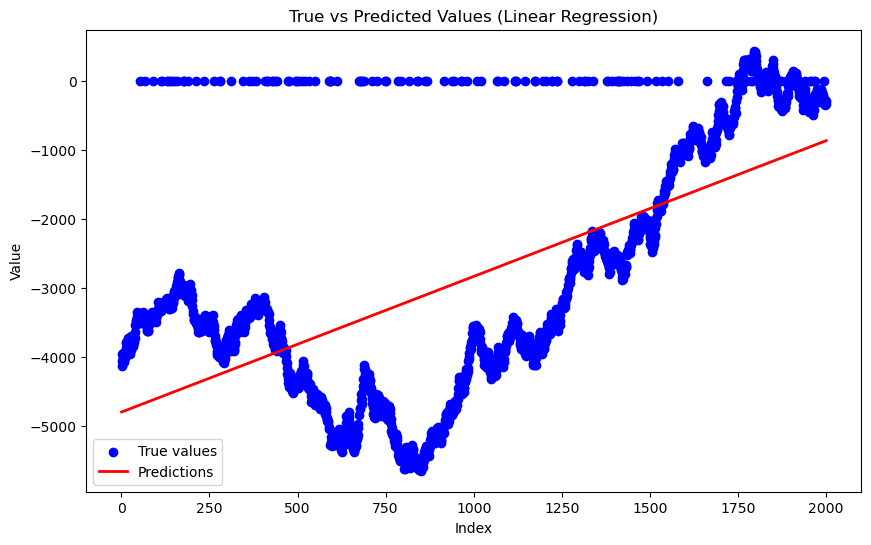

In [55]:
# رسم در فضای دو بعدی
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='blue', label='True values')
plt.plot(X, y_pred, color='red', label='Predictions', linewidth=2)
plt.xlabel('Index')
plt.ylabel('Value')
plt.title('True vs Predicted Values (Linear Regression)')
plt.legend()
plt.show()

In [59]:
X2 = np.array([np.arange(1, len(row3_cleaned) + 1)]).T 
y2 = row3_cleaned
#Linear Regression
model = LinearRegression()
model.fit(X2, y2)
y_pred2 = model.predict(X2)

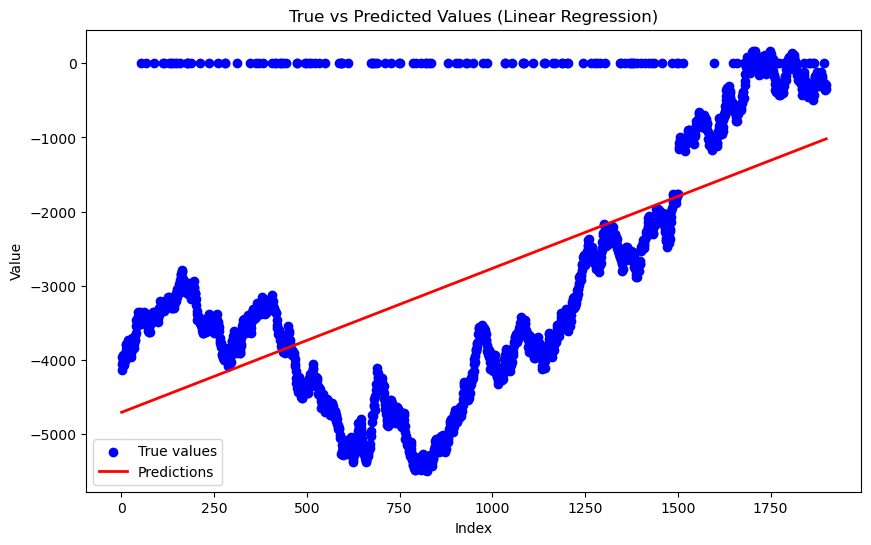

In [61]:
# رسم نتایج در فضای دو بعدی
plt.figure(figsize=(10, 6))
plt.scatter(X2, y2, color='blue', label='True values')
plt.plot(X2, y_pred2, color='red', label='Predictions', linewidth=2)
plt.xlabel('Index')
plt.ylabel('Value')
plt.title('True vs Predicted Values (Linear Regression)')
plt.legend()
plt.show()

In [63]:
X = np.array([np.arange(1, len(row3) + 1)]).T  # تبدیل به شکل ماتریس (N, 1)
y = row3

# 1. Ridge Regression
ridge_model = Ridge(alpha=1.0)  # انتخاب مقدار alpha برای رگولاریزاسیون
ridge_model.fit(X, y)

# 2. Huber Regressor
huber_model = HuberRegressor()
huber_model.fit(X, y)

# پیش‌بینی با استفاده از هر دو مدل
y_pred_ridge = ridge_model.predict(X)
y_pred_huber = huber_model.predict(X)

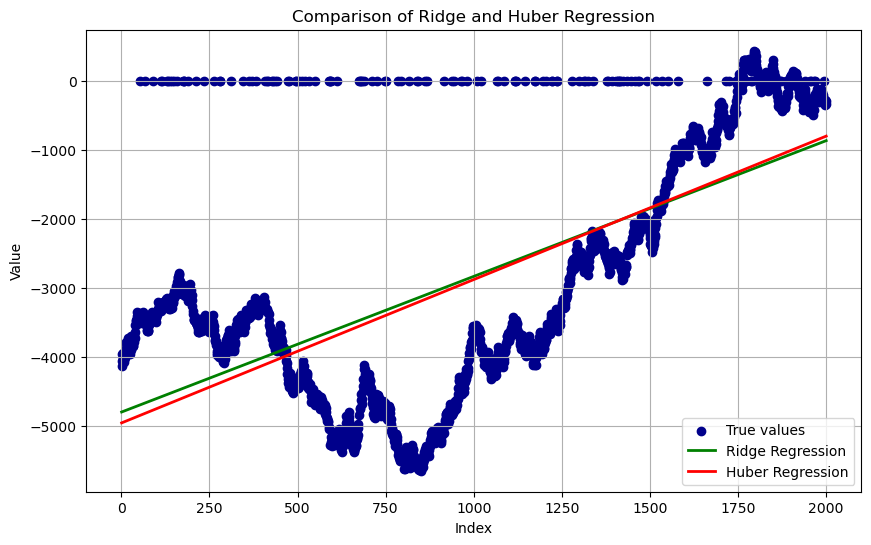

In [65]:
# رسم نتایج در فضای دو بعدی
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='DarkBlue', label='True values')

# رسم پیش‌بینی‌ها با مدل Ridge
plt.plot(X, y_pred_ridge, color='green', label='Ridge Regression', linewidth=2)

# رسم پیش‌بینی‌ها با مدل Huber
plt.plot(X, y_pred_huber, color='red', label='Huber Regression', linewidth=2)


plt.xlabel('Index')
plt.ylabel('Value')
plt.title('Comparison of Ridge and Huber Regression')
plt.legend(loc='lower right')
plt.grid()
plt.show()

In [71]:
X2 = np.array([np.arange(1, len(row3_cleaned) + 1)]).T 
y2 = row3_cleaned

# 1. Ridge Regression
ridge_model2 = Ridge(alpha=1.0)  # انتخاب مقدار alpha برای رگولاریزاسیون
ridge_model2.fit(X2, y2)

# 2. Huber Regressor
huber_model2 = HuberRegressor()
huber_model2.fit(X2, y2)

# پیش‌بینی با استفاده از هر دو مدل
y_pred_ridge2 = ridge_model2.predict(X2)
y_pred_huber2 = huber_model2.predict(X2)
y_pred_ridge2,y_pred_huber2

(array([-4706.85203144, -4704.91004099, -4702.96805055, ...,
        -1022.89615998, -1020.95416953, -1019.01217909]),
 array([-4871.64574486, -4869.58789902, -4867.53005317, ...,
         -967.91217579,  -965.85432994,  -963.79648409]))

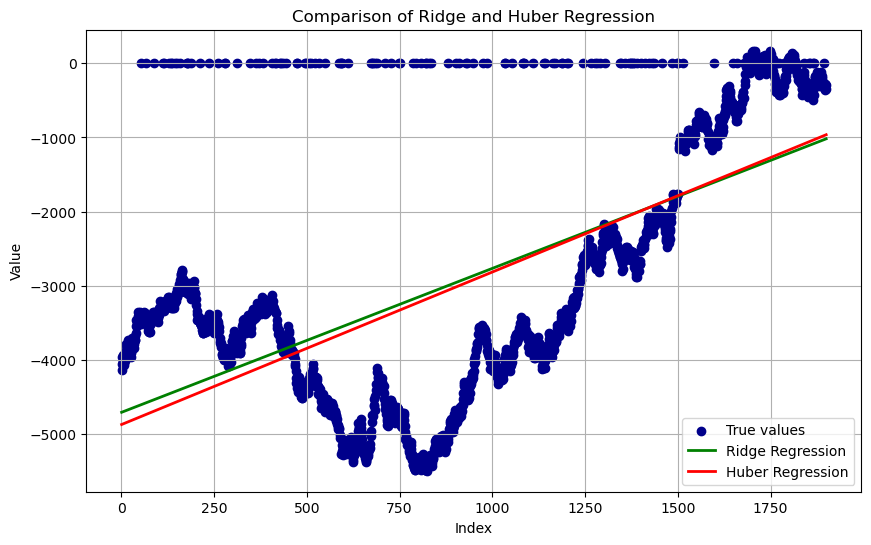

In [73]:
# رسم نتایج در فضای دو بعدی
plt.figure(figsize=(10, 6))
plt.scatter(X2, y2, color='DarkBlue', label='True values')

# رسم با مدل Ridge
plt.plot(X2, y_pred_ridge2, color='green', label='Ridge Regression', linewidth=2)

# رسم با مدل Huber
plt.plot(X2, y_pred_huber2, color='red', label='Huber Regression', linewidth=2)

plt.xlabel('Index')
plt.ylabel('Value')
plt.title('Comparison of Ridge and Huber Regression')
plt.legend(loc='lower right')
plt.grid()
plt.show()